# Logistic Regression (邏輯迴歸)

Logistic Regression (邏輯迴歸) 是一種監督式機器學習 (Supervised Machine Learning) 演算法，主要用來處理分類問題。

雖然名稱包含 Regression，但它最常見的用途不是預測連續數值，而是預測資料屬於某個類別的機率。

例如：
| 應用情境 | Features (輸入) | Target (預測目標) |
|---|---|---|
| 顧客購買預測 | 年齡、收入、網站瀏覽次數 | 是否購買 (0 / 1) |
| 學生考試預測 | 讀書時間、出席率、作業成績 | 是否及格 (0 / 1) |
| 客戶流失預測 | 使用時間、消費金額、客服次數 | 是否流失 (0 / 1) |
| 垃圾郵件分類 | 郵件文字特徵、連結數量 | 是否為垃圾郵件 (0 / 1) |
| 設備故障預測 | 溫度、震動、運轉時數 | 是否故障 (0 / 1) |

以顧客購買預測為例：
```text
顧客年齡：28 歲
每月收入：45,000 元
網站瀏覽次數：12 次
加入購物車次數：3 次
```

模型可能輸出：
```text
購買機率：0.82
預測結果：1 (會購買)
```

也就是建立以下關係：
$$
\boxed{
\text{顧客行為與基本資料}
\longrightarrow
\text{Logistic Regression}
\longrightarrow
\text{購買機率與分類結果}
}
$$

## Logistic Regression 與 Linear Regression 的差別

兩者都可以從輸入特徵建立線性組合，但輸出與使用目的不同。

| 比較項目 | Linear Regression | Logistic Regression |
|---|---|---|
| 中文名稱 | 線性迴歸 | 邏輯迴歸 |
| 主要用途 | 預測連續數值 | 預測類別 |
| Target | 數值 | 類別 |
| 典型輸出 | 25,000 元 | 購買機率 0.82 |
| 常見評估 | MAE、RMSE、R² | Accuracy、Precision、Recall、F1 |
| 主要概念 | 線性關係 | 線性組合 + Sigmoid |

假設使用 Linear Regression 預測顧客是否購買，模型可能輸出 1.3 或 -0.2，這些數值無法直接當成有效機率。

Logistic Regression 則使用 Sigmoid Function，把線性組合的結果轉換成 0 到 1 之間的數值。

![](./assets/linear_vs_logistic_regression.png)

## Logistic Regression 的運作原理

### 模型如何判斷顧客會不會購買？

假設有兩位顧客：

| 特徵 | 顧客 A | 顧客 B |
|---|---|---|
| 每月收入 | 30,000 | 65,000 |
| 網站瀏覽次數 | 2 | 15 |
| 加入購物車次數 | 0 | 4 |

直覺上，顧客 B 可能有比較高的購買意願。

Logistic Regression 會根據訓練資料，學習每個特徵對預測結果的影響，再計算顧客購買的機率。

模型內部會先建立一個線性組合：
$$
z=w_1x_1+w_2x_2+\cdots+w_nx_n+b
$$

其中：

| 符號 | 意義 |
|---|---|
| $x$ | Features (輸入特徵) |
| $w$ | 模型學習到的權重 |
| $b$ | 截距 (Intercept) |
| $z$ | 線性組合結果 |

### Sigmoid Function (S 型函數)

Logistic Regression 會將 $z$ 輸入 Sigmoid Function：
$$
\boxed{
\sigma(z)=\frac{1}{1+e^{-z}}
}
$$

Sigmoid 的作用，是將任意實數轉換成 0 到 1 之間的數值。

![](./assets/Sigmoid_Function.png)

當 \(z\) 越大，Sigmoid 輸出越接近 1；當 \(z\) 越小，輸出越接近 0。這就是 Logistic Regression 能夠進行機率預測的原因。

### Classification Threshold (分類門檻)

模型計算出機率後，還需要決定應該將資料分類為 0 還是 1。
二元分類常用 0.5 作為門檻：
$$
\hat y=
\begin{cases}
1 & P(y=1\mid X)\geq 0.5\\
0 & P(y=1\mid X)<0.5
\end{cases}
$$

例如：

| 顧客 | 預測購買機率 | 預測類別 |
|---|---|---|
| A | 0.12 | 0 (不購買) |
| B | 0.38 | 0 (不購買) |
| C | 0.67 | 1 (購買) |
| D | 0.91 | 1 (購買) |

![](./assets/logistic_regression_workflow.png)

### Decision Boundary (決策邊界)

Logistic Regression 並不是直接在資料中畫一條 S 型線來分開兩個類別。

S 型曲線描述的是線性分數如何轉換成機率。如果使用兩個 Features，模型的決策邊界通常是一條直線。

例如使用：
- X 軸：網站瀏覽次數
- Y 軸：加入購物車次數

模型可能學習到一條界線，把顧客分成「預測購買」與「預測不購買」兩個區域。

![](./assets/藍色虛線是模型在兩個特徵空間中的線性決策邊界。實際邊界由訓練資料決定.png)

## Logistic Regression 重要參數
```python
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    penalty="l2", # 正則化方式
    C=1.0, # 正則化強度的倒數
	# C 越小：正則化越強，模型係數受到更多限制
	# C 越大：正則化越弱，模型更自由地配合訓練資料。
    solver="lbfgs", # 模型最佳化演算法
    max_iter=1000, # 最大最佳化迭代次數
    class_weight=None, # 不同類別的權重
    fit_intercept=True, # 是否學習截距
    random_state=42 # 控制適用演算法的隨機性
)
```

### penalty：正則化方式

正則化 (Regularization) 可以限制模型係數的大小，降低模型過度依賴某些特徵的風險。

常見選項：

| 設定 | 說明 |
|---|---|
| `"l2"` | 限制權重過大，常見預設方式 |
| `"l1"` | 可能讓部分特徵權重變成 0 |
| `"elasticnet"` | 結合 L1 與 L2 |
| `None` | 不使用正則化 |

不同 solver 支援的正則化方式不完全相同。初學者可以先使用 penalty="l2"。

### solver：最佳化演算法

| solver | 特性 |
|---|---|
| `"lbfgs"` | 常用選項，適合多數一般資料集 |
| `"liblinear"` | 適合較小資料集，支援 L1 與 L2 |
| `"saga"` | 支援 L1、L2、Elastic Net，適合部分大型或稀疏資料 |
| `"newton-cg"` | 使用二階最佳化方法 |
| `"sag"` | 適合部分大型資料集，通常需要特徵尺度接近 |


## 實作：預測顧客是否購買商品

| 欄位 | 說明 | 類型 |
|---|---|---|
| `age` | 顧客年齡 | Numerical |
| `monthly_income` | 每月收入 (元) | Numerical |
| `website_visits` | 網站瀏覽次數 | Numerical |
| `time_on_site_min` | 網站停留時間 (分鐘) | Numerical |
| `cart_additions` | 加入購物車次數 | Numerical |
| `membership` | 會員等級 (Basic / Silver / Gold) | Categorical |
| `received_discount` | 是否收到折扣優惠 (0 / 1) | Binary |
| `purchased` | 是否購買商品 (0 / 1) | Target |

### 1. 讀取資料集


In [24]:
### 讀取資料集
import pandas as pd

df = pd.read_csv("./datas/logistic_regression_customers.csv")


### 2. 探索資料 (EDA)

先不要急著丟進模型，先確認資料長什麼樣


In [25]:
print("資料形狀：", df.shape) ### 查看資料形狀

display(df.head(10)) ### 查看前 10 筆資料

df.info() ### 查看欄位型態與缺失值
display(df.describe(include="all")) ### 查看基本統計資訊

資料形狀： (1200, 8)


,age,monthly_income,website_visits,time_on_site_min,cart_additions,membership,received_discount,purchased
0,22,68839,12,8.4,1,Basic,1,0
1,55,42581,3,11.1,0,Basic,0,0
2,49,53360,8,1.3,4,Gold,0,0
3,39,18000,14,1.8,1,Silver,1,0
4,38,26764,18,2.3,2,Basic,0,0
5,59,41859,11,14.3,3,Basic,0,0
6,22,28238,8,9.0,3,Basic,1,0
7,51,59502,6,6.7,2,Silver,1,1
8,27,81953,9,10.5,0,Silver,0,0
9,22,26409,11,19.6,4,Basic,1,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                1200 non-null   int64  
 1   monthly_income     1200 non-null   int64  
 2   website_visits     1200 non-null   int64  
 3   time_on_site_min   1200 non-null   float64
 4   cart_additions     1200 non-null   int64  
 5   membership         1200 non-null   object 
 6   received_discount  1200 non-null   int64  
 7   purchased          1200 non-null   int64  
dtypes: float64(1), int64(6), object(1)
memory usage: 75.1+ KB


,age,monthly_income,website_visits,time_on_site_min,cart_additions,membership,received_discount,purchased
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200,1200.000000,1200.000000
unique,NaN,NaN,NaN,NaN,NaN,3,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,Basic,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,564,NaN,NaN
mean,41.710000,46618.885833,9.910833,12.343500,2.124167,NaN,0.493333,0.230833
std,13.808263,16935.491899,3.081525,7.879649,1.483998,NaN,0.500164,0.421542
min,18.000000,18000.000000,3.000000,1.000000,0.000000,NaN,0.000000,0.000000
25%,30.000000,34502.750000,8.000000,6.500000,1.000000,NaN,0.000000,0.000000
50%,42.000000,46731.500000,10.000000,10.700000,2.000000,NaN,0.000000,0.000000
75%,54.000000,57770.750000,12.000000,16.100000,3.000000,NaN,1.000000,0.000000


### 3. 資料清理 (Data Cleaning)


In [26]:
print(df.isnull().sum()) ### 檢查缺失值
print("重複筆數：", df.duplicated().sum()) ### 檢查重複資料
df = df.drop_duplicates().copy() ### 移除重複資料
print(df["purchased"].value_counts()) ### 檢查 Target 分布

age                  0
monthly_income       0
website_visits       0
time_on_site_min     0
cart_additions       0
membership           0
received_discount    0
purchased            0
dtype: int64
重複筆數： 0
purchased
0    923
1    277
Name: count, dtype: int64


### 4. 選擇 Features 與 Target


In [27]:
### 選擇 Features 與 Target
### 選擇 Features
X = df[[
    "age",
    "monthly_income",
    "website_visits",
    "time_on_site_min",
    "cart_additions",
    "membership",
    "received_discount"
]].copy()


### 選擇 Target
y = df["purchased"].copy()


### 查看資料形狀
print("Features：", X.shape)
print("Target：", y.shape)

Features： (1200, 7)
Target： (1200,)


### 5. 切分 Train / Test


In [28]:
### 切分 Train / Test
from sklearn.model_selection import train_test_split


### 切分 Train 80%、Test 20%
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2, # 20% 作為測試資料
    random_state=42, # 固定隨機種子
    stratify=y # 維持 Train / Test 的類別比例
)


### 查看切分結果
print("X_train：", X_train.shape)
print("X_test：", X_test.shape)
print("y_train：", y_train.shape)
print("y_test：", y_test.shape)

X_train： (960, 7)
X_test： (240, 7)
y_train： (960,)
y_test： (240,)


### 6. 建立資料前處理 Pipeline


In [29]:
### 建立資料前處理 Pipeline
# 我們的 Features 同時包含數值與類別資料，因此使用 ColumnTransformer 建立不同的處理流程。
# - 對於數值資料：缺失值處理 -> StandardScaler
# - 對於類別資料：缺失值處理 -> OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


### 數值特徵
numeric_features = [
    "age",
    "monthly_income",
    "website_visits",
    "time_on_site_min",
    "cart_additions",
    "received_discount"
]


### 類別特徵
categorical_features = [
    "membership"
]


### 建立數值資料前處理
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), # 缺失值使用中位數補齊
    ("scaler", StandardScaler()) # 將數值特徵標準化
])


### 建立類別資料前處理
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")), # 使用眾數補齊缺失值
    ("encoder", OneHotEncoder(handle_unknown="ignore")) # 類別轉換成 One-Hot 特徵
])


### 合併數值與類別處理流程
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

### 7. 建立模型


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn import set_config

### 關閉 scikit-learn 模型的 HTML 視覺化顯示
set_config(display="text")


### 建立 Logistic Regression 模型
model = Pipeline([
    ("preprocessor", preprocessor), # 資料前處理
    ("logistic", LogisticRegression(
        penalty="l2", # 使用 L2 正則化
        C=1.0, # 正則化強度的倒數
        solver="lbfgs", # 使用 LBFGS 最佳化演算法
        max_iter=1000, # 最大最佳化迭代次數
        class_weight=None, # 不額外調整類別權重
        fit_intercept=True, # 學習截距
        random_state=42 # 固定適用演算法的隨機種子
    ))
])

model.fit(X_train, y_train) # 訓練模型
print("模型訓練完成")

d:\github\python-machine-learning\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'monthly_income',
                                                   'website_visits',
                                                   'time_on_site_min',
                                                   'cart_additions',
                                                   'received_discount']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                           

### 9. 使用模型預測


In [32]:
### 預測 Test Data 的類別
y_pred = model.predict(X_test)


### 查看前 10 筆結果
print(y_test[:10].to_list())
print(y_pred[:10])
positive_index = list(model.classes_).index(1)
y_proba_positive = model.predict_proba(X_test)[:, positive_index]


[0, 0, 0, 0, 0, 0, 0, 1, 0, 0]
[0 0 0 0 0 0 0 1 0 0]


### 10. 評估模型表現

分類模型常使用 Accuracy、Precision、Recall、F1-score。


In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


### 計算分類評估指標
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)


### 顯示結果
print(f"Accuracy：{accuracy:.4f}")
print(f"Precision：{precision:.4f}")
print(f"Recall：{recall:.4f}")
print(f"F1-score：{f1:.4f}")


### 顯示完整分類報告
print(classification_report(
    y_test,
    y_pred,
    target_names=["未購買", "已購買"],
    zero_division=0
))

Accuracy：0.8208
Precision：0.8000
Recall：0.2909
F1-score：0.4267
              precision    recall  f1-score   support

         未購買       0.82      0.98      0.89       185
         已購買       0.80      0.29      0.43        55

    accuracy                           0.82       240
   macro avg       0.81      0.63      0.66       240
weighted avg       0.82      0.82      0.79       240



### 11. 視覺化預測結果


Confusion Matrix (混淆矩陣)

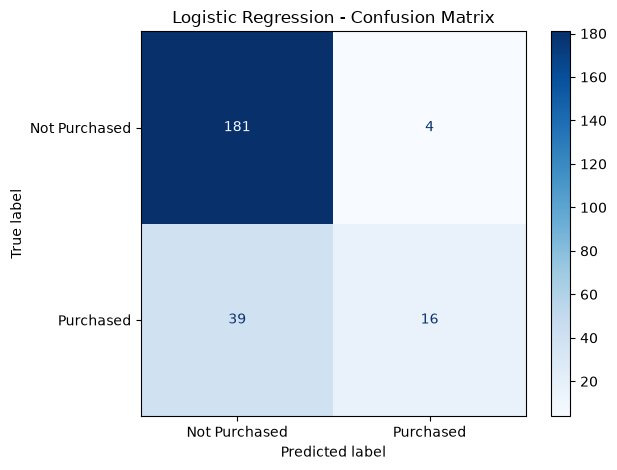

In [34]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


### 建立 Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not Purchased", "Purchased"],
    cmap="Blues",
    values_format="d"
)


### 設定圖表
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

**模型預測的購買機率，與顧客實際是否購買之間的關係**。

每個點代表一位測試集顧客。

- **X 軸**：模型預測的購買機率，越靠右表示模型認為越可能購買。
- **Y 軸**：實際結果，`0` 是未購買、`1` 是已購買。
- **紅色虛線**：分類門檻 `0.5`，右側判為購買，左側判為未購買。

用這個門檻，可以把圖分成四個區域：

| 點的位置 | 代表意思 |
|---|---|
| 左下：實際未購買、機率低於 0.5 | 預測正確（TN） |
| 右上：實際已購買、機率高於或等於 0.5 | 預測正確（TP） |
| 右下：實際未購買、機率高於或等於 0.5 | 誤判會購買（FP） |
| 左上：實際已購買、機率低於 0.5 | 漏判購買者（FN） |

理想情況是：**未購買者集中在左下，已購買者集中在右上**。越靠近 `0.5` 的點，表示模型給出的機率越接近分類門檻。

程式中的垂直位移只是讓重疊的點更容易看見，所以點會稍微偏離 `0` 或 `1`，實際類別沒有改變。

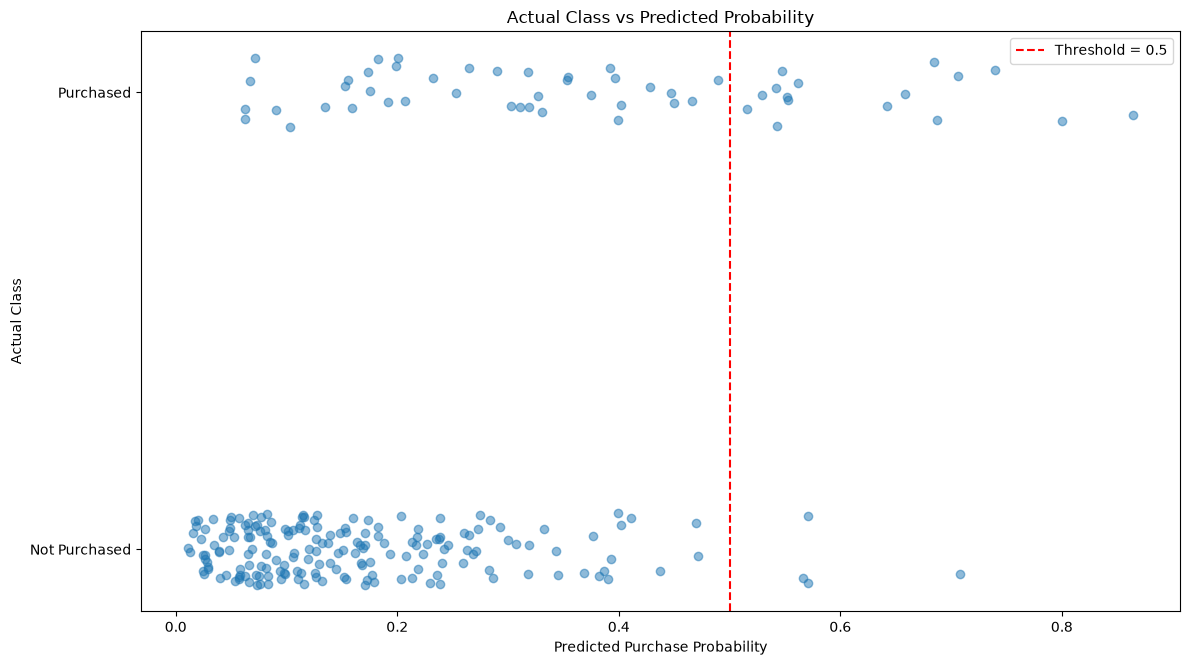

In [35]:
import matplotlib.pyplot as plt
import numpy as np

# 建立圖表
plt.figure(figsize=(12, 6.75))

# 加入少量垂直位移，避免散點完全重疊
rng = np.random.default_rng(42)
y_visual = np.asarray(y_test) + rng.uniform(-0.08, 0.08, len(y_test))

# 繪製散點圖
plt.scatter(
    y_proba_positive,
    y_visual,
    alpha=0.5
)

# 繪製分類門檻
plt.axvline(
    x=0.5,
    color="red",
    linestyle="--",
    label="Threshold = 0.5"
)

# 設定圖表
plt.xlabel("Predicted Purchase Probability")
plt.ylabel("Actual Class")
plt.yticks([0, 1], ["Not Purchased", "Purchased"])
plt.title("Actual Class vs Predicted Probability")
plt.legend()
plt.tight_layout()
plt.show()

### ROC Curve (ROC 曲線)
ROC Curve 用來觀察模型在不同分類門檻下的表現。
它的兩個座標軸是：
- X 軸：False Positive Rate (FPR)，實際有購買的人，有多少比例被模型成功找出來。
- Y 軸：True Positive Rate (TPR)，也就是 Recall，實際沒購買的人，有多少比例被模型誤判為會購買。

例如，曲線上某個點是 (0.10, 0.80)，代表該門檻下：「找出了 80% 的購買者，同時誤判了 10% 的未購買者」。

降低門檻通常會找到更多購買者，也會增加誤判；ROC 曲線讓你看到這個取捨。曲線越靠近左上角越好：找到的購買者多，誤判的未購買者少。

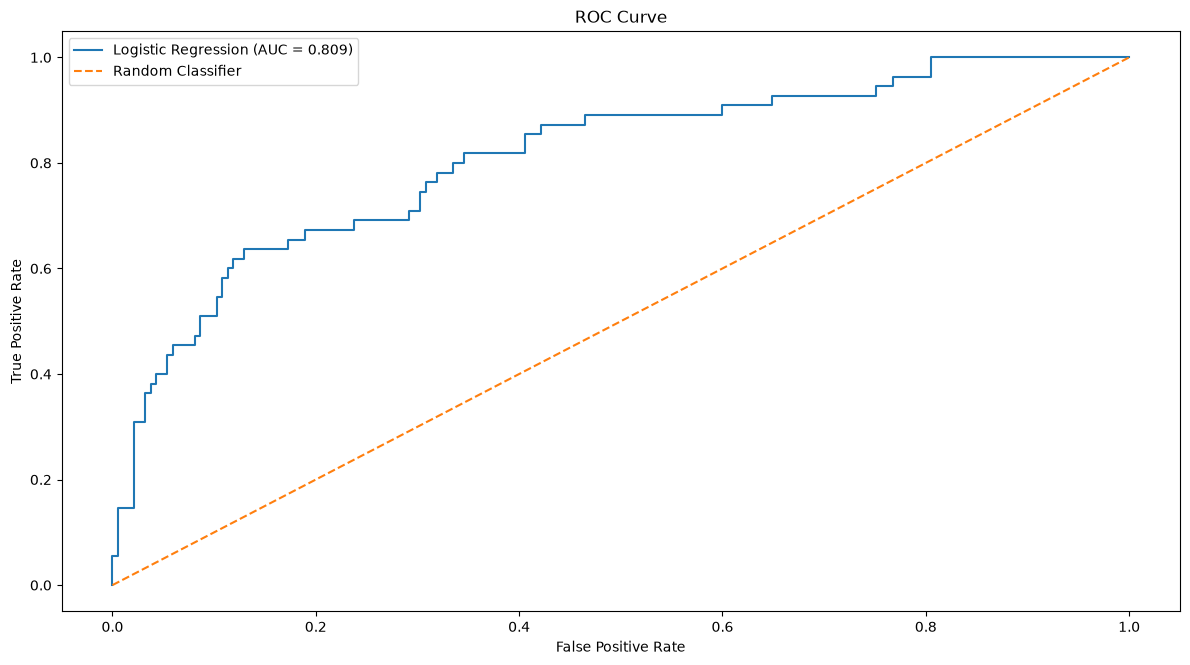

In [36]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt


### 計算 ROC Curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_proba_positive
)


### 計算 ROC AUC
roc_auc = roc_auc_score(
    y_test,
    y_proba_positive
)


### 繪製 ROC Curve
plt.figure(figsize=(12, 6.75))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)


### 繪製隨機分類參考線
plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Random Classifier"
)


### 設定圖表
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

## 作業：使用 Logistic Regression 預測道路交通事故是否涉及死亡

本次作業使用政府資料開放平臺提供的「114年傷亡道路交通事故資料」，並使用 Logistic Regression (邏輯迴歸) 建立模型，根據交通事故發生時的道路環境與交通條件，預測事故屬於 A1 或 A2 類。

- 資料集：[114年傷亡道路交通事故資料](https://data.gov.tw/dataset/177136)
- 資料來源：政府資料開放平臺、內政部警政署。

模型根據交通事故的環境與道路條件，例如：

```
天候名稱
光線名稱
速限-第1當事者
道路型態大類別名稱
路面狀況-路面狀態名稱
號誌-號誌種類名稱
發生時間
```

預測：

```
0 → A2 類事故 (有人受傷，或事故後超過 24 小時死亡)
1 → A1 類事故 (當場或事故後 24 小時內死亡)
```

也就是建立以下關係：

$$ 
\boxed{ \text{交通事故環境與道路條件} \longrightarrow \text{Logistic Regression} \longrightarrow \text{預測事故類別 (A1 / A2)} } 
$$

本次作業屬於 Binary Classification (二元分類)，模型將輸出事故屬於 A1 類的預測機率，再依分類門檻判斷事故類別。

這份資料只包含已發生的傷亡事故，因此模型並不是預測交通事故是否會發生，而是根據事故條件分類其嚴重程度。

學生最後的 Notebook 必須按照以下順序完成：

```text
1. 讀取資料集
        ↓
2. 探索資料 (EDA)
        ↓
3. 資料清理 (Data Cleaning)
        ↓
4. 選擇 Features 與 Target
        ↓
5. 切分 Train / Test
        ↓
6. 建立資料前處理 Pipeline
        ↓
7. 建立模型
        ↓
8. 訓練模型
        ↓
9. 使用模型預測
        ↓
10. 評估模型表現
    (Accuracy / Precision / Recall / F1-score)
        ↓
11. 視覺化預測結果
    (Confusion Matrix / ROC Curve)
```

作業注意事項：

- 在 EDA 階段，使用 `head()`、`info()`、`describe()`、`value_counts()` 觀察資料，並確認 A1、A2 類別的分布。
- 在 Data Cleaning 階段，處理缺失值、重複資料與不合理數值，並將事故類別轉換成二元 Target (`A1=1`、`A2=0`)。
- 切分資料時使用 `stratify=y`，盡量維持 Train / Test 的類別比例。
- 在 Pipeline 中，數值特徵使用 `SimpleImputer`、`StandardScaler`；類別特徵使用 `SimpleImputer`、`OneHotEncoder`。
- 建立模型時使用 `LogisticRegression(max_iter=1000, random_state=42)`，並為參數加入中文註解。
- 預測階段需使用 `predict()` 取得預測類別，並使用 `predict_proba()` 取得 A1 類事故的預測機率。
- 評估階段需計算 Accuracy、Precision、Recall、F1-score，特別觀察 A1 類別的 Recall。
- 視覺化階段需繪製 Confusion Matrix 與 ROC Curve，並計算 ROC AUC。
- 不得將死亡人數、受傷人數或其他直接揭露事故結果的欄位作為 Features，以避免 Data Leakage。

<p style="text-align: center;">Copyright © 2026 Wei-Cheng Chen</p>